# 03 · Bootstrap, permutación y A/B bayesiano

**Objetivo:** tres alternativas a las fórmulas cerradas, cada una con su supuesto:

| Método | Supuesto clave | Responde |
|---|---|---|
| Bootstrap | la muestra representa a la población | ¿cuánta incertidumbre tiene mi estimador? |
| Permutación | intercambiabilidad bajo $H_0$ | ¿es compatible con “no hay diferencia”? |
| Bayes | un prior y un modelo de verosimilitud | ¿qué tan probable es que B sea mejor, y por cuánto? |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_stats import (
    beta_posterior,
    bootstrap_ci,
    expected_loss,
    permutation_test,
    prob_b_beats_a,
    welch_ttest,
)

## 1. Bootstrap para un estadístico sin fórmula sencilla

El error estándar de la mediana no tiene fórmula práctica; el bootstrap lo da gratis.

In [2]:
x = rng.lognormal(3, 1, size=150)
lo, hi, boots = bootstrap_ci(x, lambda m: np.median(m, axis=1), rng=rng)
ref = stats.bootstrap((x,), np.median, method="BCa", rng=rng).confidence_interval
print(f"mediana = {np.median(x):.2f}")
print(f"percentil (desde cero): ({lo:.2f}, {hi:.2f})")
print(f"BCa (scipy):            ({ref.low:.2f}, {ref.high:.2f})")

mediana = 19.43
percentil (desde cero): (15.00, 23.83)
BCa (scipy):            (15.00, 24.03)


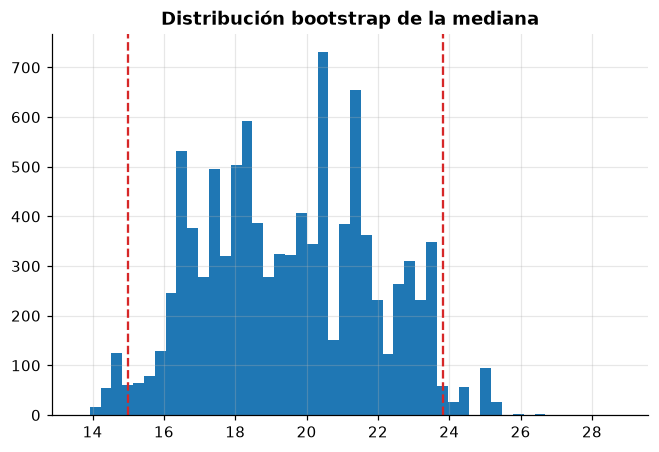

In [3]:
fig, ax = plt.subplots()
ax.hist(boots, bins=50, color="C0")
for v in (lo, hi):
    ax.axvline(v, color="C3", ls="--")
ax.set_title("Distribución bootstrap de la mediana");

BCa corrige sesgo y asimetría de la distribución bootstrap; con muestras pequeñas o
asimétricas su cobertura es mejor que la del percentil (ejercicio 2).

### Cuándo falla: el máximo

Para $X \sim U(0, \theta)$, el estimador $\max X_i$ está en el borde del soporte: las remuestras
nunca pueden superarlo y repiten el valor observado con probabilidad $1 - (1 - 1/n)^n \approx 63\%$.

In [4]:
u = rng.uniform(0, 1, size=100)
_, _, bmax = bootstrap_ci(u, lambda m: m.max(axis=1), rng=rng)
frac = np.mean(bmax == u.max())
print(f"fracción de remuestras con max* = max observado: {frac:.3f}  (teoría ≈ 0.634)")

fracción de remuestras con max* = max observado: 0.626  (teoría ≈ 0.634)


## 2. Permutación vs. Welch con muestras pequeñas y asimétricas

Ambos tests sobre el mismo par de muestras, y luego su tasa de falsos positivos por simulación.

In [5]:
a, b = rng.exponential(1, 12), rng.exponential(1, 12) + 0.8
obs, p_perm = permutation_test(a, b, rng=rng)
p_welch = welch_ttest(a, b).pvalue
print(f"diferencia = {obs:.3f} | p permutación = {p_perm:.4f} | p Welch = {p_welch:.4f}")

diferencia = 1.217 | p permutación = 0.0023 | p Welch = 0.0272


In [6]:
reps, n = 2000, 8
fp_perm = fp_welch = 0
for _ in range(reps):
    a0, b0 = rng.lognormal(0, 1.5, n), rng.lognormal(0, 1.5, n)  # misma distribución: H₀ cierta
    fp_perm += permutation_test(a0, b0, n_perm=999, rng=rng)[1] < 0.05
    fp_welch += welch_ttest(a0, b0).pvalue < 0.05
print("tasa de falsos positivos (nominal 0.05, SE ≈ 0.005):")
print(f"  permutación = {fp_perm / reps:.3f}, Welch = {fp_welch / reps:.3f}")

tasa de falsos positivos (nominal 0.05, SE ≈ 0.005):
  permutación = 0.052, Welch = 0.014


La permutación mantiene su nivel por construcción (es exacta bajo intercambiabilidad).
Welch con $n = 8$ y colas pesadas tiende a ser **conservador** aquí (rechaza menos de lo nominal):
pierde potencia. Con $n$ grande ambos coinciden.

## 3. A/B bayesiano (Beta–Binomial)

Control: 120/1000 conversiones; variante: 145/1000. Prior uniforme Beta(1, 1).

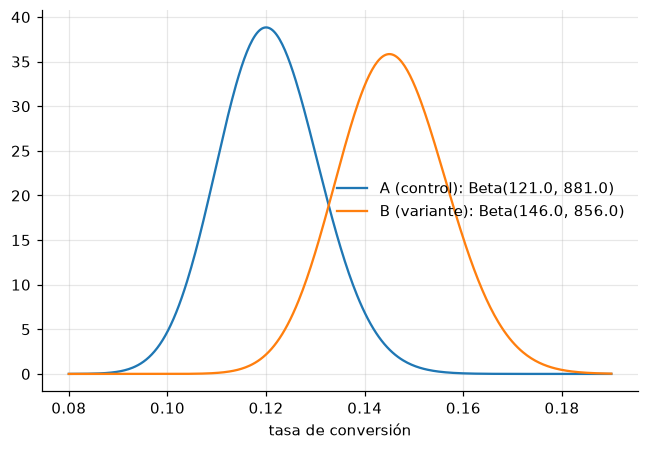

In [7]:
post_a, post_b = beta_posterior(120, 1000), beta_posterior(145, 1000)
g = np.linspace(0.08, 0.19, 400)
fig, ax = plt.subplots()
for post, name in [(post_a, "A (control)"), (post_b, "B (variante)")]:
    ax.plot(g, stats.beta.pdf(g, *post), label=f"{name}: Beta{post}")
ax.set_xlabel("tasa de conversión")
ax.legend();

In [8]:
p_b = prob_b_beats_a(post_a, post_b, rng=rng)
loss_a, loss_b = expected_loss(post_a, post_b, rng=rng)
p_freq = stats.chi2_contingency([[120, 880], [145, 855]], correction=False)[1]
print(f"P(B > A | datos)   = {p_b:.3f}")
print(f"pérdida esperada   : elegir A = {loss_a:.4f}, elegir B = {loss_b:.4f}")
print(
    f"p-valor bilateral  = {p_freq:.3f}  (≈ 2·(1 − P(B > A)) con prior plano: {2 * (1 - p_b):.3f})"
)

P(B > A | datos)   = 0.951
pérdida esperada   : elegir A = 0.0253, elegir B = 0.0003
p-valor bilateral  = 0.099  (≈ 2·(1 − P(B > A)) con prior plano: 0.098)


Con prior plano y $n$ grande, $P(B > A)$ y el p-valor unilateral se relacionan
casi uno a uno: la diferencia está en la **pregunta** que se responde y en cómo se usa para decidir.

### Sensibilidad al prior

Un prior informativo centrado en 12 % (equivale a ~1000 observaciones previas) frena
las conclusiones apresuradas cuando hay pocos datos.

In [9]:
informative = (120, 880)
for n in [100, 1000, 10_000]:
    sa, sb = int(0.12 * n), int(0.145 * n)
    flat = prob_b_beats_a(beta_posterior(sa, n), beta_posterior(sb, n), rng=rng)
    info = prob_b_beats_a(
        beta_posterior(sa, n, informative), beta_posterior(sb, n, informative), rng=rng
    )
    print(f"n = {n:>6}: P(B > A) prior plano = {flat:.3f} | prior informativo = {info:.3f}")

n =    100: P(B > A) prior plano = 0.659 | prior informativo = 0.552
n =   1000: P(B > A) prior plano = 0.949 | prior informativo = 0.884
n =  10000: P(B > A) prior plano = 1.000 | prior informativo = 1.000


## Para llevar

- Bootstrap: incertidumbre de casi cualquier estimador; desconfiar en bordes del soporte y con $n$ chico.
- Permutación: exacta bajo $H_0$ de intercambiabilidad; ideal con muestras pequeñas.
- Bayes: responde la pregunta de negocio directamente; el prior importa menos cuanto más datos.